In [ ]:
!pip install xgboost imbalanced-learn

In [52]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.metrics import classification_report, roc_auc_score, precision_recall_curve, average_precision_score, confusion_matrix, ConfusionMatrixDisplay
from imblearn.over_sampling import SMOTE


In [ ]:
data = pd.read_csv("data/data_preprocessed.csv")
print("Shape du dataset :", data.shape)

Shape du dataset : (357952, 92)


Tri temporel et découpage train/val/test

In [54]:
data_processed = data.sort_values(by='time_of_day')

train_size = int(len(data_processed) * 0.7)
val_size   = int(len(data_processed) * 0.15)

train_data = data_processed.iloc[:train_size]
val_data   = data_processed.iloc[train_size:train_size + val_size]
test_data  = data_processed.iloc[train_size + val_size:]

X_train = train_data.drop(columns=['normality'])
y_train = train_data['normality']

X_val = val_data.drop(columns=['normality'])
y_val = val_data['normality']

X_test = test_data.drop(columns=['normality'])
y_test = test_data['normality']


Application de SMOTE

In [55]:
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)
print(f"Shape original: {X_train.shape}, Shape après SMOTE: {X_train_res.shape}")


Shape original: (250566, 91), Shape après SMOTE: (487236, 91)


Préparation du DMatrix pour XGBoost

In [56]:
dtrain = xgb.DMatrix(X_train_res, label=y_train_res)
dval = xgb.DMatrix(X_val, label=y_val)


Paramètres XGBoost et entraînement

In [57]:
params = {
    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    'max_depth': 5,
    'learning_rate': 0.05,
    'subsample': 0.8,
    'colsample_bytree': 0.8,
    'gamma': 1,
    'min_child_weight': 1,
    'seed': 42,
    'scale_pos_weight': 1
}

watchlist = [(dtrain, 'train'), (dval, 'eval')]
num_boost_round = 1000
early_stopping_rounds = 50

bst = xgb.train(
    params,
    dtrain,
    num_boost_round=num_boost_round,
    evals=watchlist,
    early_stopping_rounds=early_stopping_rounds,
    verbose_eval=20
)


[0]	train-auc:0.99665	eval-auc:0.39923
[20]	train-auc:0.99985	eval-auc:0.22720
[40]	train-auc:0.99990	eval-auc:0.22809
[52]	train-auc:0.99993	eval-auc:0.22812


Prédiction et optimisation du seuil via la PR curve

In [58]:
y_val_proba = bst.predict(dval)

# PR curve
precision, recall, thresholds = precision_recall_curve(y_val, y_val_proba)
f1_scores = 2 * precision * recall / (precision + recall + 1e-6)  # éviter div0
best_idx = np.argmax(f1_scores)
best_thresh = thresholds[best_idx]
print(f"Seuil optimal (F1 max): {best_thresh:.3f}")

y_val_pred = (y_val_proba > best_thresh).astype(int)


Seuil optimal (F1 max): 0.455


Évaluation du modèle

In [59]:
roc_auc = roc_auc_score(y_val, y_val_proba)
pr_auc = average_precision_score(y_val, y_val_proba)

print("=== Classification Report ===")
print(classification_report(y_val, y_val_pred))
print(f"ROC-AUC: {roc_auc:.4f}")
print(f"PR-AUC: {pr_auc:.4f}")


=== Classification Report ===
              precision    recall  f1-score   support

           0       0.96      1.00      0.98     51124
           1       0.92      0.17      0.29      2568

    accuracy                           0.96     53692
   macro avg       0.94      0.59      0.64     53692
weighted avg       0.96      0.96      0.95     53692

ROC-AUC: 0.2281
PR-AUC: 0.2409


Matrice de confusion

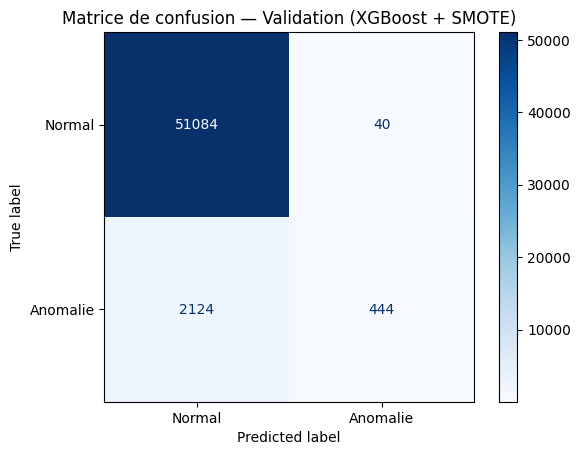

In [60]:
cm = confusion_matrix(y_val, y_val_pred)
disp = ConfusionMatrixDisplay(cm, display_labels=["Normal", "Anomalie"])
disp.plot(cmap="Blues")
plt.title("Matrice de confusion — Validation (XGBoost + SMOTE)")
plt.show()


Courbe ROC

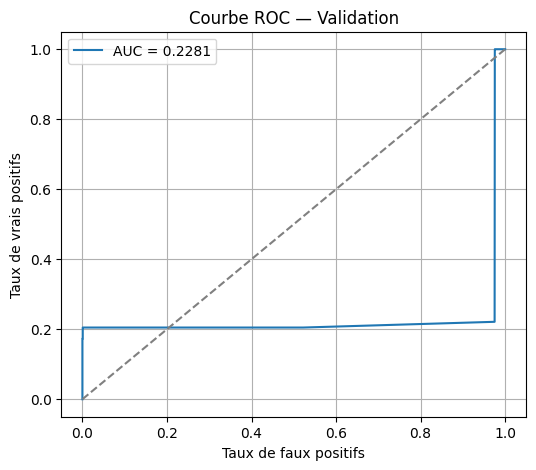

In [61]:
fpr, tpr, _ = roc_curve(y_val, y_val_proba)
plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.4f}")
plt.plot([0,1],[0,1],"--", color="gray")
plt.xlabel("Taux de faux positifs")
plt.ylabel("Taux de vrais positifs")
plt.title("Courbe ROC — Validation")
plt.legend()
plt.grid(True)
plt.show()


Courbe PR (Precision-Recall)

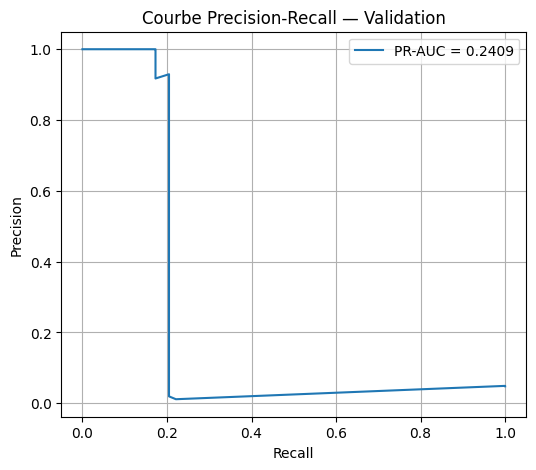

In [62]:
plt.figure(figsize=(6,5))
plt.plot(recall, precision, label=f"PR-AUC = {pr_auc:.4f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Courbe Precision-Recall — Validation")
plt.legend()
plt.grid(True)
plt.show()
